# Raids and displacement

Lead 3 asks whether enforcement removes garimpo or moves it. E12 found that garimpo
cases rose where IBAMA's deterrence collapsed after 2019. This notebook looks at the other
side: IBAMA's garimpo raids, which surge from 2021 (`output/research/mining_economics_leads.md`,
E14).

- **Raids.** IBAMA's garimpo destruction and seizure terms (`enforcement`), dated to the
  day, by the municipality where they took place.
- **Outcome.** SIVEP garimpo cases by infection municipality and notification month
  (`malaria`; 2025 onward from the preliminary release), all, local and incoming, and
  non-garimpo malaria as the placebo.
- **Episodes.** A municipality's first month with a raid term after 12 months without
  one, from 2019 until 12 months before SIVEP's last month.
  - Samples: all raids; large raids (3+ terms in the month); and malaria-visible raids
    (12+ garimpo cases in the 12 months before). SIVEP only sees garimpo where malaria
    is transmitted.
- **Stacked event study,** months −12 to +12 around each raid:
  - *own:* the raided municipality;
  - *neighbours:* each bordering municipality not itself raided in the window.

  Controls are the sample municipalities neither raided in the window nor bordering the
  raided one. Episode × municipality and episode × month FE; SEs clustered by
  municipality.
- **Triple difference.** Raids follow local malaria peaks, so garimpo is also measured
  against non-garimpo malaria in the same municipality-month.
- **Displacement ratio.** Garimpo cases gained by all neighbours per case lost at the
  raid, from the pooled estimates in levels.

Code: `src/analysis/garimpo_raids.py`. Tables go to `output/analysis/garimpo/raids/`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import garimpo_raids as R

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda value: f"{value:.4g}")

OUT = PROJECT_ROOT / "output" / "analysis" / "garimpo" / "raids"
OUT.mkdir(parents=True, exist_ok=True)

panel, raids, adjacency = R.load_inputs()
table = R.episodes(raids, months=R.episode_window(panel))
table["pre_cases"] = R.pre_cases(table, panel)
samples = R.episode_samples(table, panel)
table.to_csv(OUT / "episodes.csv", index=False)
print(panel["mun_id"].nunique(), "sample municipalities,", panel["month"].nunique(), "months to",
      panel["month"].max().strftime("%Y-%m"), "; episodes", *R.episode_window(panel))
display(pd.DataFrame({name: [len(part), part["mun_id"].nunique(), int(part["raid_terms"].sum()),
                             part["pre_cases"].median()]
                      for name, part in samples.items()},
                     index=["episodes", "municipalities", "raid terms in the raid month", "median cases before"]))

INFO:src.data.sources.biomes.preprocess:Excluding 2 non-municipality GADM ADM2 polygon(s) (e.g. lagoons).


267 sample municipalities, 100 months to 2026-04 ; episodes 2019-01 2025-04


,all raids,large raids (3+ terms),malaria-visible (12+ cases before)
episodes,129,53,51
municipalities,89,48,34
raid terms in the raid month,778,662,317
median cases before,4,10,49


## 1. Raids and cases

In [2]:
yearly = pd.DataFrame({
    "raid terms": raids.groupby(raids["month"].dt.year)["raid_terms"].sum(),
    "raided municipalities": raids.groupby(raids["month"].dt.year)["mun_id"].nunique(),
    "episodes": table.groupby(table["month"].dt.year).size(),
    "garimpo cases (sample)": panel.groupby(panel["month"].dt.year)["inf_garimpo"].sum(),
})
display(yearly.fillna(0).astype(int))
display(table.assign(state=table["mun_id"].str[:2], year=table["month"].dt.year).pivot_table(
    index="state", columns="year", values="mun_id", aggfunc="count", fill_value=0))
display(table["pre_cases"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1))

,raid terms,raided municipalities,episodes,garimpo cases (sample)
month,,,,
2018,96,29,0,4417
2019,74,19,16,8663
2020,129,29,22,15126
2021,365,34,19,19829
2022,264,37,19,22284
2023,726,48,27,18193
2024,1080,46,22,14609
2025,993,60,4,12376
2026,422,27,0,4635


year,2019,2020,2021,2022,2023,2024,2025
state,,,,,,,
11,1,2,1,2,2,2,1
13,3,1,2,5,12,3,3
14,1,3,5,2,1,2,0
15,2,8,5,4,4,4,0
16,1,2,1,0,1,2,0
17,1,1,2,0,2,1,0
21,1,0,0,0,2,1,0
51,6,5,3,6,3,7,0


count     129
mean    120.2
std     447.1
min         0
25%         0
50%         4
75%        28
90%     141.6
max      3178
Name: pre_cases, dtype: float64

**Reading the results.** Raids surge late, repeat in the same places, and many hit places
where SIVEP sees little garimpo.
- *Raid terms (destruction and seizure):* 74–129 a year in 2018–20, 365 (2021), 264
  (2022), 726 (2023), 1,080 (2024) and 993 (2025).
- *Episodes:* 129 from 2019 to April 2025, in 89 municipalities: Mato Grosso 30,
  Amazonas 29, Pará 27, Roraima 14.
- *Repeated raids:* the 2,073 raid terms of 2024–25 give only 26 episodes, because IBAMA
  raids the same municipalities month after month. Sustained campaigns therefore fall
  outside a design built on a first raid after a clean year.
- *Malaria visibility:*
  - A quarter of the episodes had no garimpo case in the 12 months before the raid; the
    median had 4.
  - The 51 malaria-visible episodes (34 municipalities) had a median of 49.

## 2. At the raid and next door

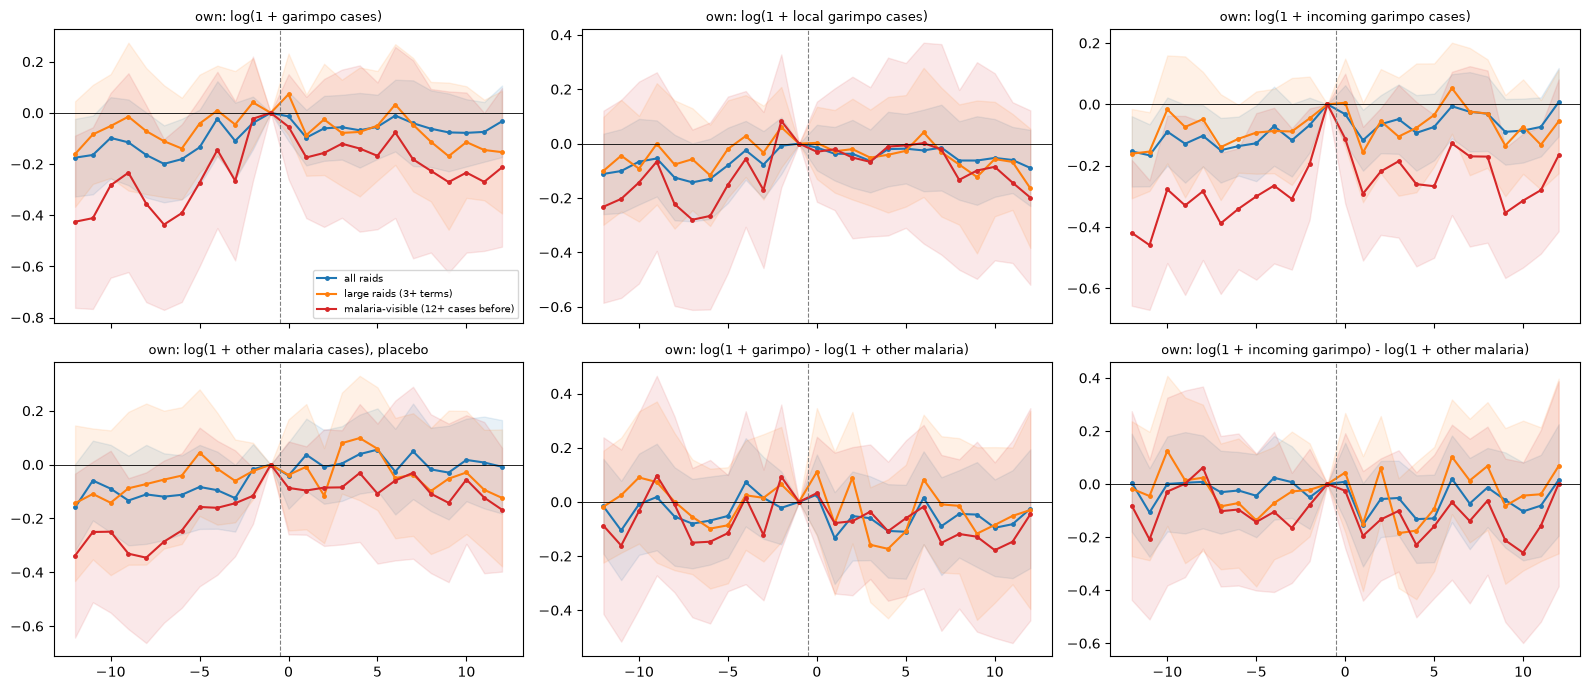

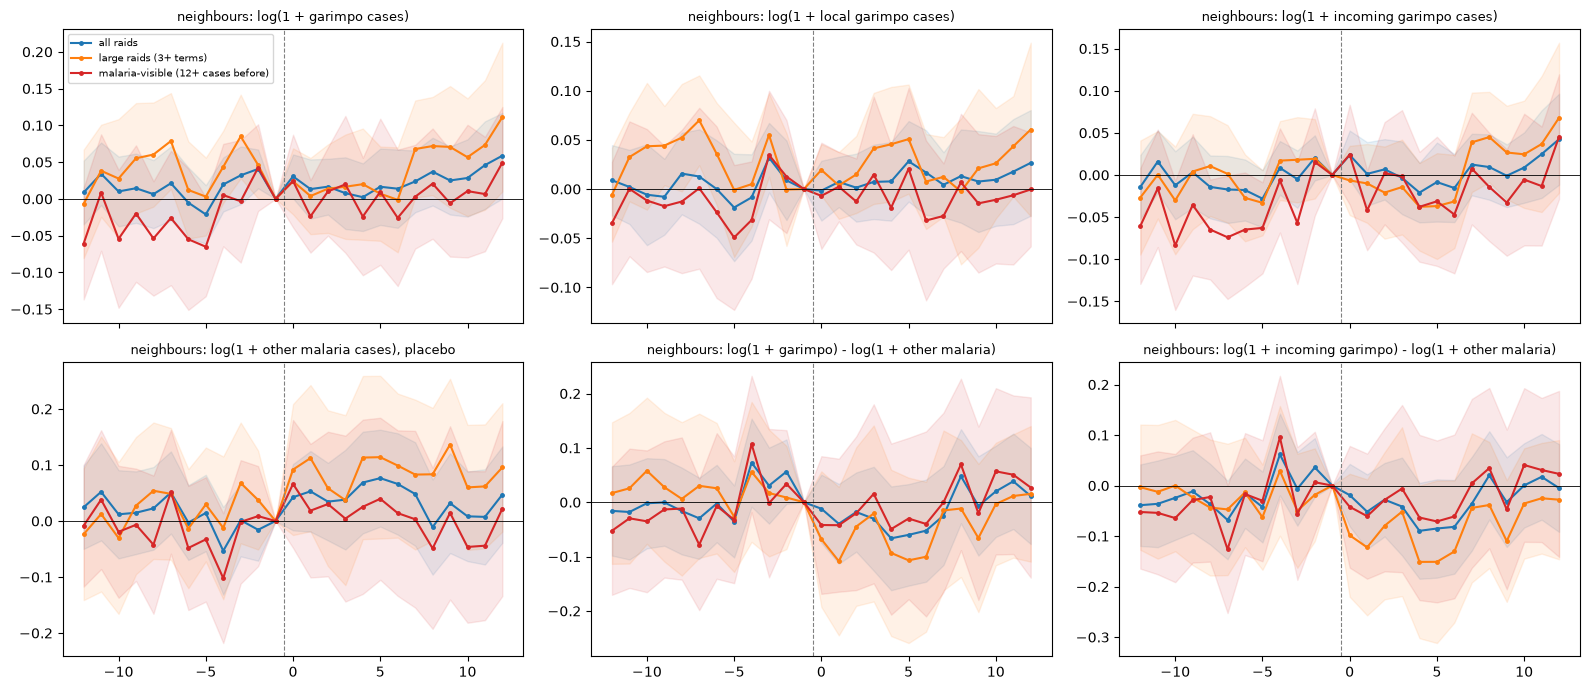

window                                                                -12..-7  -6..-2  -1 (base)   0..2   3..5   6..8  9..12
design     sample                             outcome                                                                       
own        all raids                          log1p_garimpo            -0.153  -0.098          0 -0.057  -0.06 -0.038 -0.066
                                              log1p_garimpo_local        -0.1  -0.064          0  -0.03 -0.034 -0.034 -0.066
                                              log1p_garimpo_incoming   -0.132  -0.104          0 -0.072 -0.072  -0.02 -0.061
                                              log1p_other_malaria      -0.112  -0.086          0 -0.004  0.033  0.002 -0.003
                                              garimpo_vs_other         -0.041  -0.011          0 -0.053 -0.093  -0.04 -0.062
                                              incoming_vs_other         -0.02  -0.018          0 -0.067 -0.105 -0.022 -0.057
           large raids (3+ terms)             log1p_garimpo            -0.082  -0.035          0 -0.013 -0.068 -0.042 -0.146
                                              log1p_garimpo_local      -0.062  -0.016          0 -0.015  -0.04 -0.022 -0.103
                                              log1p_garimpo_incoming   -0.099  -0.085          0 -0.069 -0.072 -0.001 -0.099
                                              log1p_other_malaria      -0.102  -0.019          0 -0.054  0.079 -0.062 -0.075
                                              garimpo_vs_other          0.019  -0.016          0   0.04 -0.147   0.02 -0.071
                                              incoming_vs_other         0.003  -0.066          0 -0.015 -0.151  0.061 -0.024
           malaria-visible (12+ cases before) log1p_garimpo            -0.358   -0.22          0 -0.129 -0.143 -0.162 -0.247
                                              log1p_garimpo_local      -0.191  -0.112          0 -0.034 -0.028 -0.051 -0.132
                                              log1p_garimpo_incoming    -0.36  -0.282          0 -0.208 -0.238 -0.156 -0.279
                                              log1p_other_malaria        -0.3  -0.165          0  -0.09 -0.074 -0.066 -0.122
                                              garimpo_vs_other         -0.058  -0.055          0 -0.039 -0.068 -0.096 -0.125
                                              incoming_vs_other         -0.06  -0.118          0 -0.118 -0.163  -0.09 -0.157
neighbours all raids                          log1p_garimpo             0.016   0.013          0   0.02  0.009  0.025   0.04
                                              log1p_garimpo_local       0.004   0.003          0  0.002  0.014  0.011  0.015
                                              log1p_garimpo_incoming   -0.006  -0.004          0  0.011 -0.011  0.002  0.019
                                              log1p_other_malaria       0.029  -0.011          0  0.043  0.061  0.034  0.024
                                              garimpo_vs_other         -0.014   0.024          0 -0.023 -0.052  -0.01  0.016
                                              incoming_vs_other        -0.036   0.007          0 -0.033 -0.072 -0.032 -0.005
           large raids (3+ terms)             log1p_garimpo             0.042   0.038          0  0.014  0.015  0.046  0.078
                                              log1p_garimpo_local       0.039   0.019          0  0.013  0.046  0.006  0.038
                                              log1p_garimpo_incoming   -0.007  -0.001          0 -0.013  -0.03  0.017  0.039
                                              log1p_other_malaria       0.015   0.022          0  0.088  0.088  0.088  0.089
                                              garimpo_vs_other          0.027   0.016          0 -0.074 -0.074 -0.042 -0.011
                                              incoming_vs_other        -0.022  -0.023          0   -0.1 -0.118 -0.071  -0.05


In [3]:
OUTCOMES = ["log1p_garimpo", "log1p_garimpo_local", "log1p_garimpo_incoming", "log1p_other_malaria",
            "garimpo_vs_other", "incoming_vs_other"]
stacks = {(design, name): R.stack(panel, part, raids, adjacency, design)
          for design in R.DESIGNS for name, part in samples.items()}
studies = pd.concat([R.event_study(stacked, outcome).assign(design=design, sample=name)
                     for (design, name), stacked in stacks.items() for outcome in OUTCOMES], ignore_index=True)
studies.to_csv(OUT / "event_studies.csv", index=False)

for design in R.DESIGNS:
    fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
    for ax, outcome in zip(axes.ravel(), OUTCOMES):
        for (name, color) in zip(samples, ("C0", "C1", "C3")):
            part = studies[(studies.design == design) & (studies["sample"] == name) & (studies.outcome == outcome)]
            ax.plot(part.rel, part.estimate, marker="o", ms=2.5, color=color, label=name)
            ax.fill_between(part.rel, part.estimate - 1.96 * part.se, part.estimate + 1.96 * part.se, color=color,
                            alpha=0.1)
        ax.axvline(-0.5, color="grey", lw=0.8, ls="--")
        ax.axhline(0, color="black", lw=0.6)
        ax.set_title(f"{design}: {R.OUTCOMES[outcome]}", fontsize=9)
    axes[0, 0].legend(fontsize=7)
    fig.tight_layout()
    plt.show()

quarters = studies.assign(window=pd.cut(studies.rel, [-13, -7, -2, -1, 2, 5, 8, 12],
                                         labels=["-12..-7", "-6..-2", "-1 (base)", "0..2", "3..5", "6..8", "9..12"]))
display(quarters.pivot_table(index="window", columns=["design", "sample", "outcome"], values="estimate",
                             observed=True, sort=False).round(3).T)

**Reading the results.** IBAMA raids where malaria is rising, and the rise stops for garimpo
and other malaria alike.
- *At the raid, garimpo cases:*
  - Before: below the month before the raid, by −0.10 to −0.15 in all raids and −0.22
    to −0.36 in malaria-visible ones. Cases grow into the raid.
  - After: they stay near that level: −0.04 to −0.07 in all raids, −0.13 to −0.25 in
    visible ones.
- *The placebo:* non-garimpo malaria follows the same path in the visible sample: −0.30
  and −0.17 before, −0.07 to −0.12 after. Raids are timed to local malaria peaks, so the
  plain event study cannot separate a raid effect.
- *Against other malaria* (the triple difference):
  - Garimpo is close to flat before the raid (−0.06 to +0.02).
  - It is slightly lower after: −0.04 to −0.09 in all raids, and −0.04 to −0.13 in
    visible ones, falling over the year.
  - Incoming cases in visible raids are −0.09 to −0.16 after, but already −0.12 in months
    −6 to −2.
- *Next door:* garimpo cases in bordering municipalities move −0.03 to +0.08, and against
  other malaria −0.07 to +0.03. After large raids, incoming cases dip against other
  malaria (−0.05 to −0.12), the opposite of displacement.

## 3. Pooled effects and the displacement ratio

Treated × months 0 to +12 against months −12 to −1.

In [4]:
pooled = pd.DataFrame([{"design": design, "sample": name, **R.pooled(stacked, outcome)}
                       for (design, name), stacked in stacks.items() for outcome in [*OUTCOMES, "inf_garimpo"]])
pooled.to_csv(OUT / "pooled.csv", index=False)
for value in ("estimate", "p"):
    display(pooled.pivot_table(index=["design", "sample"], columns="outcome", values=value, sort=False).round(3))
display(pooled[["design", "sample", "n_episodes", "n_treated_units", "n_obs"]].drop_duplicates(["design", "sample"]))

levels = pooled[pooled.outcome == "inf_garimpo"].set_index(["design", "sample"])
ratios = pd.Series({name: R.displacement_ratio(levels.loc[("own", name)], levels.loc[("neighbours", name)])
                    for name in samples}, name="neighbour cases gained per case lost at the raid")
display(ratios.round(2))

outcome                                        log1p_garimpo  log1p_garimpo_local  log1p_garimpo_incoming  log1p_other_malaria  garimpo_vs_other  incoming_vs_other  inf_garimpo
design     sample                                                                                                                                                               
own        all raids                                   0.061                0.034                   0.053                0.098            -0.037             -0.045        4.261
           large raids (3+ terms)                     -0.017               -0.012                   0.022                0.027            -0.045             -0.006        6.473
           malaria-visible (12+ cases before)          0.095                0.076                   0.073                0.128            -0.033             -0.055        10.67
neighbours all raids                                   0.011                0.008                   0.011                0.029            -0.018             -0.018        0.212
           large raids (3+ terms)                      0.004               -0.001                    0.01                0.072            -0.067             -0.062       -0.109
           malaria-visible (12+ cases before)          0.029                0.004                   0.031                0.021             0.008               0.01        0.343

outcome                                        log1p_garimpo  log1p_garimpo_local  log1p_garimpo_incoming  log1p_other_malaria  garimpo_vs_other  incoming_vs_other  inf_garimpo
design     sample                                                                                                                                                               
own        all raids                                   0.116                0.353                   0.121                0.058              0.39              0.325         0.11
           large raids (3+ terms)                      0.842                0.891                   0.767                0.768             0.564              0.945        0.285
           malaria-visible (12+ cases before)          0.311                0.398                   0.378                0.194             0.649              0.505        0.112
neighbours all raids                                    0.39                 0.37                   0.286                  0.3             0.511              0.521        0.237
           large raids (3+ terms)                      0.858                0.947                   0.594                0.161             0.183              0.238        0.722
           malaria-visible (12+ cases before)          0.217                0.791                   0.121                0.657             0.864              0.838        0.211

,design,sample,n_episodes,n_treated_units,n_obs
0,own,all raids,129,129,676500
7,own,large raids (3+ terms),53,53,277450
14,own,malaria-visible (12+ cases before),51,51,269475
21,neighbours,all raids,121,392,640000
28,neighbours,large raids (3+ terms),49,160,258625
35,neighbours,malaria-visible (12+ cases before),46,169,245525


all raids                            NaN
large raids (3+ terms)               NaN
malaria-visible (12+ cases before)   NaN
Name: neighbour cases gained per case lost at the raid, dtype: float64

**Reading the results.** No measurable effect of a raid on garimpo cases within a year,
at the site or next door.
- *Own municipality, pooled post-raid against pre-raid:*
  - garimpo cases +0.06 (p 0.12) in all raids and +0.10 (p 0.31) in visible ones, which
    is the pre-raid rise;
  - against other malaria −0.04 (p 0.39), −0.05 for large raids (p 0.56) and −0.03 for
    visible ones (p 0.65).
- *Neighbours:*
  - garimpo cases +0.004 to +0.03 (p ≥ 0.22);
  - against other malaria −0.07 to +0.01 (p ≥ 0.18).
- *Displacement ratio:* not defined, since no raid sample loses cases at the site in
  levels (+4 to +11 cases per municipality-month, p ≥ 0.11).
- *Power:* against other malaria, the 95% interval at the raid reaches about −0.12 in all
  raids and −0.17 in visible ones, so a fall of that size cannot be ruled out.
- *What it says:* within a year, a single raid does not measurably reduce garimpo malaria
  where it happens, and crews do not show up in bordering municipalities.
  - Crews may move farther or leave the region.
  - A raid may stop operations without stopping infection among those who stay.
  - SIVEP may be too coarse for one raid.
  - The sustained campaigns of 2023–25 need a design on raid intensity, not first raids.